# Project 1: Social Media Engagement & Sentiment Analysis


## Step 1 · Load the data and keep a backup

In [32]:
import os, shutil, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
os.makedirs("submission", exist_ok=True)

# If your column names differ, map them here (leave {} for the GitHub dataset), e.g.
# RENAME = {"likeCount": "likes", "replyCount": "comments", "textDisplay": "text", "publishedAt": "timestamp"}
RENAME = {
    "like_count": "likes",
    "reply_count": "comments",
    "comment_text": "text",
    "published_at": "timestamp"
}

# Pick the CSV from your computer
from google.colab import files
uploaded = files.upload()
CSV_PATH = list(uploaded.keys())[0]
print("Using file:", CSV_PATH)

shutil.copy(CSV_PATH, "ORIGINAL_backup_" + os.path.basename(CSV_PATH))  # untouched copy
raw = pd.read_csv(CSV_PATH)
df = raw.rename(columns=RENAME).copy()
has = lambda *cols: all(c in df.columns for c in cols)
df["timestamp"] = pd.to_datetime(df["timestamp"])
print("Loaded:", df.shape)
df.head()

Saving comments_raw.csv to comments_raw (1).csv
Using file: comments_raw (1).csv
Loaded: (4453, 9)


,comment_id,text,likes,comments,timestamp,video_id,video_title,channel,content_type
0,Ugz8v8E_CSXe9ukBbp94AaABAg,Starting 😢\nEnding 🤣,21108,77,2024-12-22 16:16:40+00:00,DEdWUNVdLHY,iPhone vs Samsung 😂,Shahveer Jafry,comparison
1,UgyfCIfSRYvw_BoQ8Jx4AaABAg,The way shahveer react 😂😂 make it so real... \...,6706,22,2024-12-18 15:59:24+00:00,DEdWUNVdLHY,iPhone vs Samsung 😂,Shahveer Jafry,comparison
2,UgzWI9Xiq8gXcsv7S4B4AaABAg,Starting😮\nEnding😂,1957,1,2024-12-24 14:49:00+00:00,DEdWUNVdLHY,iPhone vs Samsung 😂,Shahveer Jafry,comparison
3,UgwJ8aPdSQS6-oYejyR4AaABAg,The way the dead man opened his eyes when the ...,98,1,2025-05-02 15:43:09+00:00,DEdWUNVdLHY,iPhone vs Samsung 😂,Shahveer Jafry,comparison
4,UgyVvW28nNHcQTuKRI14AaABAg,The ringtone was so loud that bro came back to...,832,8,2025-04-27 09:09:06+00:00,DEdWUNVdLHY,iPhone vs Samsung 😂,Shahveer Jafry,comparison


## Step 2 · What is one record, and what does each column mean?

In [33]:
meanings = {
    "comment_id": "Unique identifier of the comment",
    "comment_text": "Text of the comment",
    "like_count": "Number of likes received by the comment",
    "reply_count": "Number of replies to the comment",
    "published_at": "Date and time when the comment was published",
    "video_id": "Unique identifier of the YouTube video",
    "video_title": "Title of the YouTube video",
    "channel": "YouTube channel that published the video",
    "content_type": "Category or type of video content",
    "language": "Language of the comment",
    "hour": "Hour when the comment was published",
    "weekday": "Day of the week when the comment was published",
    "engagement": "Total engagement received by the comment",
    "sentiment": "Sentiment classification of the comment",
    "sentiment_conf": "Confidence score of the sentiment classification",
}

def kind(s):
    if pd.api.types.is_numeric_dtype(s):
        return "Numerical"
    if pd.api.types.is_datetime64_any_dtype(s):
        return "Date/time"
    return "Text/Categorical"

data_dictionary = pd.DataFrame({
    "column": df.columns,
    "dtype_as_loaded": [str(t) for t in df.dtypes],
    "type_guess": [kind(df[c]) for c in df.columns],
    "example_value": [
        df[c].dropna().iloc[0] if df[c].notna().any() else None
        for c in df.columns
    ],
    "meaning": [
        meanings.get(c, "TODO: describe this column")
        for c in df.columns
    ],
})

data_dictionary.to_csv("submission/data_dictionary.csv", index=False)

data_dictionary

,column,dtype_as_loaded,type_guess,example_value,meaning
0,comment_id,object,Text/Categorical,Ugz8v8E_CSXe9ukBbp94AaABAg,Unique identifier of the comment
1,text,object,Text/Categorical,Starting 😢\nEnding 🤣,TODO: describe this column
2,likes,int64,Numerical,21108,TODO: describe this column
3,comments,int64,Numerical,77,TODO: describe this column
4,timestamp,"datetime64[ns, UTC]",Date/time,2024-12-22 16:16:40+00:00,TODO: describe this column
5,video_id,object,Text/Categorical,DEdWUNVdLHY,Unique identifier of the YouTube video
6,video_title,object,Text/Categorical,iPhone vs Samsung 😂,Title of the YouTube video
7,channel,object,Text/Categorical,Shahveer Jafry,YouTube channel that published the video
8,content_type,object,Text/Categorical,comparison,Category or type of video content


In [34]:
for c in ["channel", "language", "sentiment", "content_type"]:
    if c in df.columns:
        print(c, "->", df[c].nunique(),
              "unique:", list(df[c].dropna().unique()[:15]))

df[["comment_id", "channel", "video_title", "content_type"]].head(10)

channel -> 29 unique: ['Shahveer Jafry', 'VideoWaliSarkar', 'Tech Burner', 'BABLOO LAHORI', 'Techno Ruhez', 'Trakin Tech', 'MAS TECH', 'TECHOOB', 'Mr Bods', 'Samsung Pakistan', 'Mohit Balani', 'M7 🤳🏻', 'ReviewsPK', 'Spec Check', 'Mansab Kazmi']
content_type -> 6 unique: ['comparison', 'price_update', 'unboxing', 'review', 'other', 'brand_official']


,comment_id,channel,video_title,content_type
0,Ugz8v8E_CSXe9ukBbp94AaABAg,Shahveer Jafry,iPhone vs Samsung 😂,comparison
1,UgyfCIfSRYvw_BoQ8Jx4AaABAg,Shahveer Jafry,iPhone vs Samsung 😂,comparison
2,UgzWI9Xiq8gXcsv7S4B4AaABAg,Shahveer Jafry,iPhone vs Samsung 😂,comparison
3,UgwJ8aPdSQS6-oYejyR4AaABAg,Shahveer Jafry,iPhone vs Samsung 😂,comparison
4,UgyVvW28nNHcQTuKRI14AaABAg,Shahveer Jafry,iPhone vs Samsung 😂,comparison
5,UgzUAD9h9r5YWStx17t4AaABAg,Shahveer Jafry,iPhone vs Samsung 😂,comparison
6,UgyBSfrkXvvIMhiZuMN4AaABAg,Shahveer Jafry,iPhone vs Samsung 😂,comparison
7,UgwVvHdoDmlYU9v7wLV4AaABAg,Shahveer Jafry,iPhone vs Samsung 😂,comparison
8,Ugy2ylUAD5CsSq6uQL14AaABAg,Shahveer Jafry,iPhone vs Samsung 😂,comparison
9,UgyRd8CqE44I4Ut6dwh4AaABAg,Shahveer Jafry,iPhone vs Samsung 😂,comparison


## Step 3 · Inspect before cleaning (record count, types, missing values, duplicates)

In [35]:
print("Rows, columns:", df.shape)

display(df.dtypes)

display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

if has("comment_id"):
    print("Duplicate comment_id values:",
          df["comment_id"].duplicated().sum())

display(df.describe(include="all").T)

# Look for numbers stored as text and impossible values BEFORE cleaning
for c in ["likes", "comments", "engagement", "sentiment_conf", "hour"]:

    if c in df.columns and not pd.api.types.is_numeric_dtype(df[c]):
        print(f"'{c}' is stored as text. Will convert.")

    if c in df.columns and pd.api.types.is_numeric_dtype(df[c]) and (df[c] < 0).any():
        print(f"'{c}' has {(df[c] < 0).sum()} negative values. Will review.")

Rows, columns: (4453, 9)


,0
comment_id,object
text,object
likes,int64
comments,int64
timestamp,"datetime64[ns, UTC]"
video_id,object
video_title,object
channel,object
content_type,object


,0
comment_id,0
text,0
likes,0
comments,0
timestamp,0
video_id,0
video_title,0
channel,0
content_type,0


Duplicate rows: 0
Duplicate comment_id values: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
comment_id,4453,4453,Ugz8v8E_CSXe9ukBbp94AaABAg,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,4453,4258,❤,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,4453.0,NaN,NaN,NaN,13.275994,0.0,0.0,0.0,1.0,21108.0,345.74784
comments,4453.0,NaN,NaN,NaN,0.567033,0.0,0.0,0.0,0.0,248.0,4.595332
timestamp,4453,NaN,NaN,NaN,2025-09-03 21:43:43.302941952+00:00,2017-02-19 21:46:52+00:00,2024-08-09 11:03:43+00:00,2025-11-08 11:50:17+00:00,2026-08-18 12:50:09+00:00,2026-10-20 14:43:04+00:00,NaN
video_id,4453,49,DEdWUNVdLHY,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
video_title,4453,49,iPhone vs Samsung 😂,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel,4453,29,VideoWaliSarkar,1636,NaN,NaN,NaN,NaN,NaN,NaN,NaN
content_type,4453,6,comparison,1477,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 4 · Clean (every change is logged)

Rule used here: **do not silently delete rows.** Impossible values become *missing* (NaN) and are reported.
A blank metric may mean "not collected", not zero.

In [36]:
log = []

def note(step, n, detail=""):
    log.append({
        "step": step,
        "rows_or_cells_affected": int(n),
        "detail": detail
    })

# 1) Convert numerical columns stored as text into numbers
num_cols = [
    c for c in ["likes", "comments", "engagement", "sentiment_conf", "hour"]
    if c in df.columns
]

for c in num_cols:
    before_na = df[c].isna().sum()

    df[c] = pd.to_numeric(
        df[c].astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce"
    )

    note(
        f"convert {c} to numeric",
        df[c].isna().sum() - before_na,
        "values that could not be parsed became NaN"
    )

# 2) Negative counts are impossible -> NaN
count_cols = ["likes", "comments", "engagement"]

for c in count_cols:
    if c in df.columns:
        neg = (df[c] < 0).sum()
        df.loc[df[c] < 0, c] = np.nan
        note(f"negative {c} set to NaN", neg)

# 3) Timestamp -> datetime (invalid -> NaT)
if has("timestamp"):
    before_na = df["timestamp"].isna().sum()

    df["timestamp"] = pd.to_datetime(
        df["timestamp"], errors="coerce"
    )

    note(
        "parse timestamp",
        df["timestamp"].isna().sum() - before_na,
        "invalid dates became NaT"
    )

# 4) Standardise text categories
for c in ["channel", "language", "sentiment", "content_type", "weekday"]:
    if c in df.columns:
        df[c] = df[c].astype("string").str.strip().str.lower()

if has("text"):
    df["text"] = df["text"].astype("string").str.strip()

# 5) Duplicates (logged, then removed)
n = df.duplicated().sum()
df = df.drop_duplicates()
note("drop exact duplicate rows", n)

if has("comment_id"):
    n = df["comment_id"].duplicated().sum()
    df = df.drop_duplicates(subset="comment_id", keep="first")
    note("drop repeated comment_id (keep first)", n)

# 6) Save cleaning log
cleaning_log = pd.DataFrame(log)

cleaning_log.to_csv("submission/cleaning_log.csv", index=False)

display(cleaning_log)

print("Rows after cleaning:", len(df))

print("Missing values after cleaning:")
print(df.isna().sum()[lambda s: s > 0])

,step,rows_or_cells_affected,detail
0,convert likes to numeric,0,values that could not be parsed became NaN
1,convert comments to numeric,0,values that could not be parsed became NaN
2,negative likes set to NaN,0,
3,negative comments set to NaN,0,
4,parse timestamp,0,invalid dates became NaT
5,drop exact duplicate rows,0,
6,drop repeated comment_id (keep first),0,


Rows after cleaning: 4453
Missing values after cleaning:
Series([], dtype: int64)


## Step 5 · Summary statistics

Two required statistics are produced below. Only analyses the columns can support are run.

In [37]:
# Engagement metrics available in your dataset
metrics = [c for c in ["likes", "comments", "engagement"] if c in df.columns]

# Statistic 1: Descriptive statistics of engagement numbers
desc = df[metrics].describe().T
desc["median"] = df[metrics].median()

display(desc)

# Save descriptive statistics
desc.to_csv("submission/descriptive_statistics.csv")


# Statistic 2: Group counts AND medians by channel
if has("channel"):
    by_channel = df.groupby("channel")[metrics].agg(
        ["count", "mean", "median"]
    ).round(1)

    display(by_channel)

    by_channel.to_csv("submission/stats_by_channel.csv")


# Statistic 3: Sentiment distribution
if has("sentiment"):
    display(
        df["sentiment"].value_counts(dropna=False).to_frame("records")
    )


# Are a few comments dominating the averages?
if has("likes"):
    total_likes = df["likes"].sum()

    if total_likes > 0:
        top10 = (
            df["likes"].nlargest(max(1, int(len(df) * 0.10))).sum()
            / total_likes
        )
    else:
        top10 = 0

    print(f"Mean likes: {df['likes'].mean():.1f} | "
          f"Median likes: {df['likes'].median():.1f}")

    print(f"Top 10% of comments account for {top10:.0%} of all likes")


# Correlation between likes and comments (Spearman)
if has("likes", "comments"):
    correlation = df[["likes", "comments"]].corr(
        method="spearman"
    ).iloc[0, 1]

    print("Correlation likes vs comments (Spearman):",
          round(correlation, 3))

,count,mean,std,min,25%,50%,75%,max,median
likes,4453.0,13.275994,345.747840,0.0,0.0,0.0,1.0,21108.0,0.0
comments,4453.0,0.567033,4.595332,0.0,0.0,0.0,0.0,248.0,0.0


likes               comments            
                          count   mean median    count mean median
channel                                                           
babloo lahori               150    5.2    1.0      150  0.8    0.0
bilal mobile's                1    0.0    0.0        1  0.0    0.0
creater99                     9    0.2    0.0        9  0.4    0.0
hocane tech                  11    0.1    0.0       11  0.2    0.0
inspecx                      15    3.3    3.0       15  1.3    1.0
m7 🤳🏻                       150    1.4    0.0      150  0.6    0.0
mansab kazmi                 78    0.4    0.0       78  1.3    1.0
mas tech                    600    1.3    0.0      600  0.2    0.0
mob shopping                 14    0.0    0.0       14  1.1    1.0
mohit balani                150    4.6    1.0      150  1.1    0.0
mr bods                     150    4.0    0.0      150  0.4    0.0
nationalmobileqta            44    1.0    0.0       44  0.4    0.0
reviewsmasterpk              10    0.1    0.0       10  0.3    0.0
reviewspk                   295    0.5    0.0      295  0.4    0.0
reviewsrk                    12    0.5    0.0       12  0.2    0.0
rubi mobiles tech updates    11    0.3    0.0       11  0.0    0.0
samsung mobile rwp            1    0.0    0.0        1  0.0    0.0
samsung pakistan            219    7.0    0.0      219  0.4    0.0
shahveer jafry              150  280.4    1.5      150  3.1    0.0
spec check                  112    4.8    1.0      112  0.6    0.0
tech burner                 150   19.6    2.0      150  1.3    0.0
tech delight                  1    0.0    0.0        1  0.0    0.0
techno mushi                  5    0.4    0.0        5  0.0    0.0
techno ruhez                150   14.3    1.0      150  0.8    0.0
techoob                     150    5.8    0.0      150  0.6    0.0
top mobile 4u                 2    0.0    0.0        2  0.5    0.5
trakin tech                 150    8.7    0.0      150  0.8    0.0
urdupoint.com                27    0.2    0.0       27  0.0    0.0
videowalisarkar            1636    2.7    0.0     1636  0.3    0.0

Mean likes: 13.3 | Median likes: 0.0
Top 10% of comments account for 97% of all likes
Correlation likes vs comments (Spearman): 0.398


## Step 6 · Charts (at least two are required)

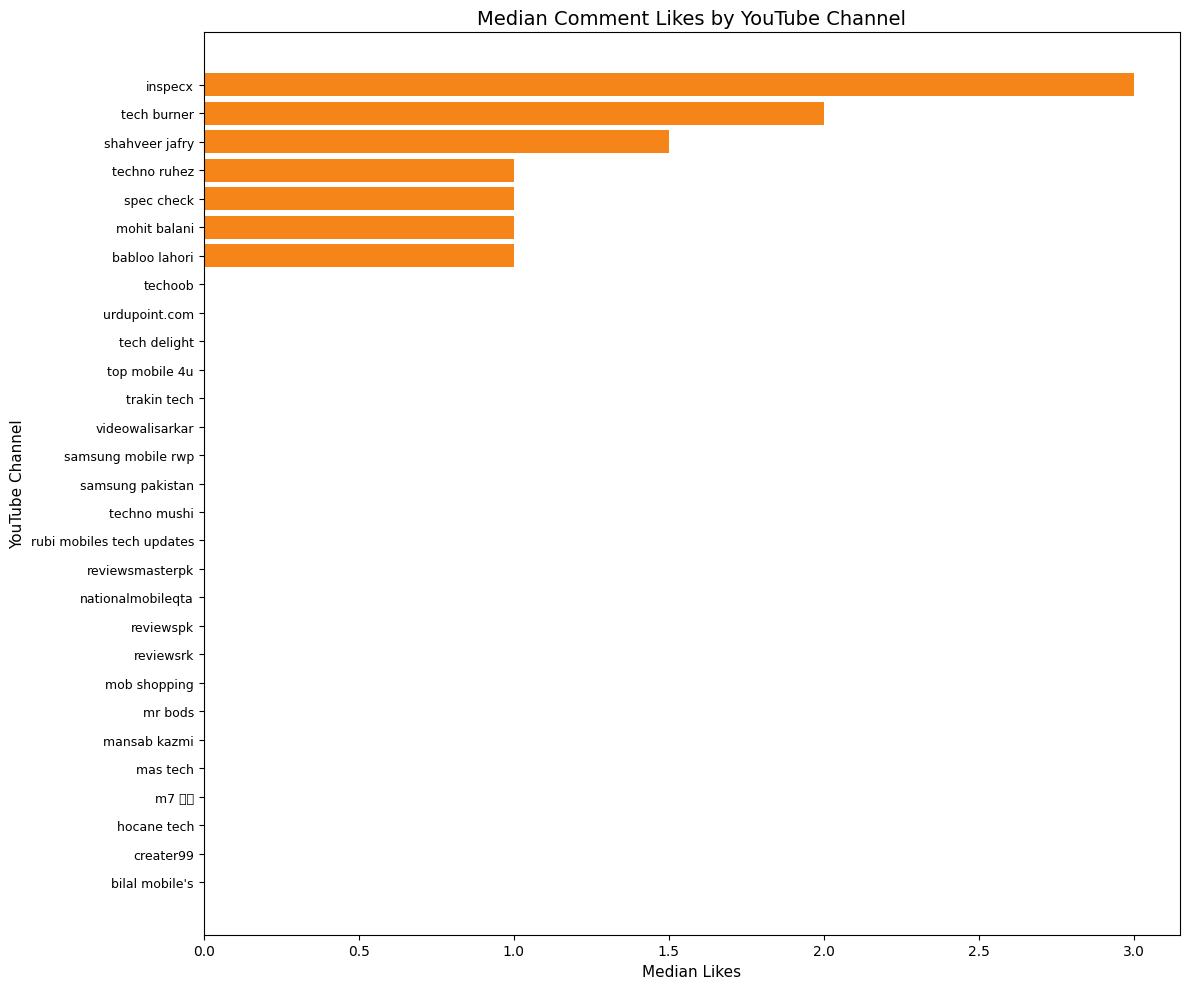

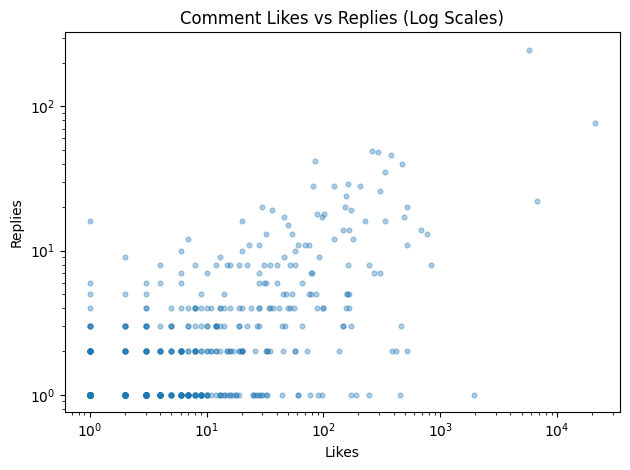

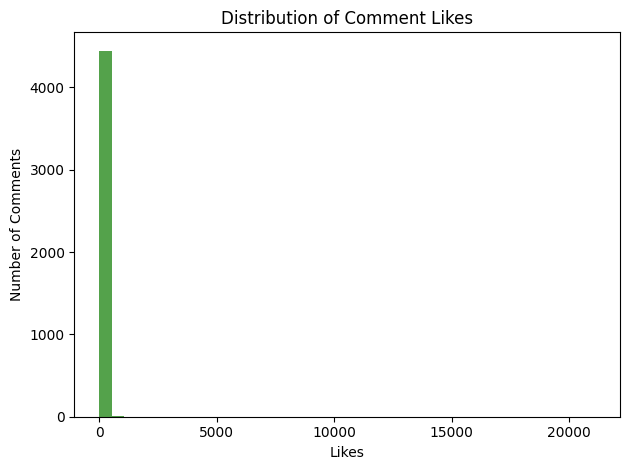

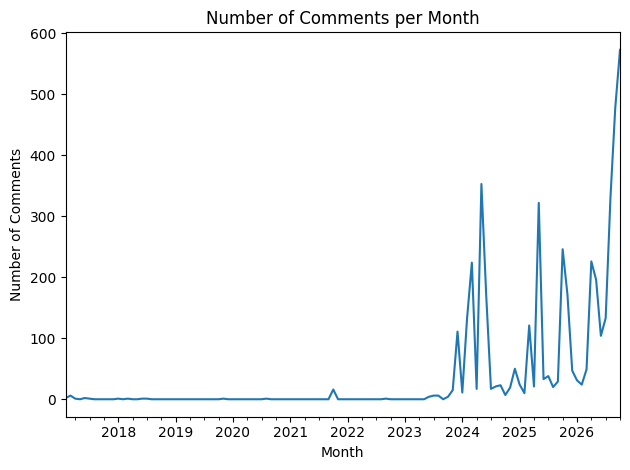

In [38]:
# Chart 1: Records per sentiment
if has("sentiment"):
    ax = df["sentiment"].value_counts().plot(
        kind="bar", color="#4C78A8"
    )

    plt.title("Comment Count by Sentiment")
    plt.xlabel("Sentiment")
    plt.ylabel("Number of Comments")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig("submission/chart1_sentiment_counts.png", dpi=150)
    plt.show()


# Chart 2: Median likes by YouTube channel (horizontal bar chart)

if has("channel", "likes"):

    g = df.groupby("channel")["likes"].agg(
        ["median", "count"]
    ).sort_values("median", ascending=True)

    plt.figure(figsize=(12, 10))

    plt.barh(g.index, g["median"], color="#F58518")

    plt.title("Median Comment Likes by YouTube Channel", fontsize=14)
    plt.xlabel("Median Likes", fontsize=11)
    plt.ylabel("YouTube Channel", fontsize=11)

    plt.yticks(fontsize=9)

    plt.tight_layout()

    plt.savefig(
        "submission/chart2_median_likes_by_channel.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()


# Chart 3: Likes vs comments (log scale)
if has("likes", "comments"):
    d = df[(df["likes"] > 0) & (df["comments"] > 0)]

    plt.scatter(d["likes"], d["comments"], alpha=0.35, s=12)

    plt.xscale("log")
    plt.yscale("log")

    plt.title("Comment Likes vs Replies (Log Scales)")
    plt.xlabel("Likes")
    plt.ylabel("Replies")

    plt.tight_layout()
    plt.savefig("submission/chart3_likes_vs_comments.png", dpi=150)
    plt.show()


# Chart 4: Distribution of comment likes
if has("likes"):
    df["likes"].dropna().plot(
        kind="hist", bins=40, color="#54A24B"
    )

    plt.title("Distribution of Comment Likes")
    plt.xlabel("Likes")
    plt.ylabel("Number of Comments")

    plt.tight_layout()
    plt.savefig("submission/chart4_likes_distribution.png", dpi=150)
    plt.show()


# Chart 5: Comments per month (only if timestamps are valid)
if has("timestamp") and df["timestamp"].notna().sum() > 0:

    df.dropna(subset=["timestamp"]).set_index(
        "timestamp"
    ).resample("MS").size().plot()

    plt.title("Number of Comments per Month")
    plt.xlabel("Month")
    plt.ylabel("Number of Comments")

    plt.tight_layout()
    plt.savefig("submission/chart5_comments_per_month.png", dpi=150)
    plt.show()

## Step 7 · Business interpretation

**Finding 1: Engagement differs across YouTube channels and content types**

Evidence: The dataset contains comments from 29 YouTube channels, 49 videos and 6 content types. Comparing median likes, replies and engagement across channels and content types can help identify which channels and types of videos generate stronger audience interaction. The actual rankings should be based on the descriptive statistics calculated from the dataset.

**Finding 2: Comment likes and replies can reveal engagement patterns**

Evidence: Comparing likes and replies using Spearman correlation helps determine whether comments receiving more likes also tend to receive more replies. Sentiment classification provides an additional way to understand whether audience reactions are positive, negative or neutral.

**Recommendation**

Based on this dataset, a content creator or marketing team could compare engagement across YouTube channels and video content types to identify patterns in audience interaction. They could use these findings to guide future content decisions and investigate which types of videos encourage more likes and replies. They should also consider audience sentiment rather than relying on engagement counts alone.

**Limitation**

The dataset contains 4,148 YouTube comments, but it does not include video views, impressions or audience size. Therefore, the analysis cannot establish a true engagement rate or determine whether a channel performs better after adjusting for its audience size. The dataset's source, license and collection method should also be documented. Since the analysis is observational, it cannot establish that a particular channel or content type causes higher engagement.

**Why a scalable tool might help**

At the current dataset size, pandas is sufficient for performing the analysis. In my scaling experiment, the 2-million-row dataset used approximately 1.30 GB of memory, took 8.242 seconds to load and required 0.379 seconds for the group-by analysis. This shows that pandas handled all tested dataset sizes successfully in Google Colab. A distributed processing tool such as Apache Spark would become worth investigating if the dataset grew beyond the memory or processing capacity of a single machine.

## Step 8 · Scaling experiment (this is a workload test, not new evidence)

In [39]:
RUN_2M = True   # set True only if your Colab session has enough RAM; it can be slow

def analysis(d):
    t = time.time()

    # Group comment engagement metrics by YouTube channel
    if has("channel") and metrics:
        d.groupby("channel")[metrics].agg(["mean", "median"])

    # Count comments by sentiment
    if has("sentiment"):
        d["sentiment"].value_counts()

    return time.time() - t


targets = [2_000, 20_000, 200_000] + ([2_000_000] if RUN_2M else [])

rows = []

for target in targets:
    reps = int(np.ceil(target / len(df)))
    big = pd.concat([df] * reps, ignore_index=True).head(target)

    big.to_csv("scaling_test.csv", index=False)
    size_mb = os.path.getsize("scaling_test.csv") / 1e6

    t0 = time.time()
    reloaded = pd.read_csv("scaling_test.csv")
    load_s = time.time() - t0

    rows.append({
        "rows": target,
        "file_MB": round(size_mb, 1),
        "load_seconds": round(load_s, 3),
        "analysis_seconds": round(analysis(big), 3),
        "memory_MB": round(big.memory_usage(deep=True).sum() / 1e6, 1)
    })

    del big, reloaded

scaling = pd.DataFrame(rows)
scaling.to_csv("submission/scaling_results.csv", index=False)

display(scaling)

os.remove("scaling_test.csv")

,rows,file_MB,load_seconds,analysis_seconds,memory_MB
0,2000,0.4,0.019,0.006,1.3
1,20000,4.4,0.124,0.012,13.0
2,200000,43.6,0.716,0.041,129.8
3,2000000,436.2,8.242,0.379,1298.0


**Scaling Experiment Results**

I repeated the original 4,148-row YouTube comments dataset to create 2,000, 20,000, 200,000, and 2,000,000-row versions. This was a scaling experiment, not additional real-world data. File size and memory usage grew approximately in proportion to the number of rows. At 2 million rows, the CSV file was 436.2 MB, and the DataFrame used approximately 1.30 GB of memory. Loading the dataset took 8.242 seconds, while the group-by analysis took only 0.379 seconds.

Pandas successfully handled all tested dataset sizes in Google Colab. Therefore, the experiment did not identify a specific row count at which Pandas stops working. Based on the observed memory growth, I estimate that processing 100 million rows could require approximately 65 GB of memory. This would exceed the RAM available on many typical machines. At that scale, or when processing data continuously across multiple machines, a distributed processing tool such as Apache Spark would be worth investigating.

## Step 9 · Short ML preview (conceptual demo only)

Each demo avoids leakage: no target metric is used to build its own predictor, and predictive work uses a train/test split.

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# CLASSIFICATION: predict the sentiment label from YouTube comment text
if has("text", "sentiment"):

    d = df.dropna(subset=["text", "sentiment"]).copy()

    # Remove empty comments
    d = d[d["text"].str.strip() != ""]

    # Split comment text and sentiment labels into training and testing sets
    Xtr, Xte, ytr, yte = train_test_split(
        d["text"].astype(str),
        d["sentiment"],
        test_size=0.25,
        random_state=42,
        stratify=d["sentiment"]
    )

    # Convert comment text into numerical TF-IDF features
    vec = TfidfVectorizer(
        max_features=3000,
        ngram_range=(1, 2),
        stop_words="english"
    )

    # Train Logistic Regression model
    clf = LogisticRegression(max_iter=1000).fit(
        vec.fit_transform(Xtr), ytr
    )

    # Predict sentiment on the test data
    predictions = clf.predict(vec.transform(Xte))

    # Display model performance
    print("Sentiment Classification Report:")
    print(classification_report(yte, predictions))

In [41]:
# CLUSTERING: group YouTube comments with similar engagement profiles

feat = [c for c in ["likes", "comments", "engagement"] if c in df.columns]

if len(feat) >= 2:
    d = df.dropna(subset=feat).copy()

    # Scale numeric engagement values after log transformation
    Z = StandardScaler().fit_transform(np.log1p(d[feat]))

    # Create 3 clusters
    d["cluster"] = KMeans(
        n_clusters=3,
        n_init=10,
        random_state=42
    ).fit_predict(Z)

    # Display median engagement values and number of comments in each cluster
    display(
        d.groupby("cluster")[feat].median().round(0).join(
            d["cluster"].value_counts().rename("comments_count")
        )
    )


# REGRESSION: predict log(likes) using other comment engagement metrics

if has("likes", "comments", "engagement"):
    d = df.dropna(subset=["likes", "comments", "engagement"]).copy()

    # Use comments and engagement to predict likes
    X = np.log1p(d[["comments", "engagement"]])
    y = np.log1p(d["likes"])

    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.25, random_state=42
    )

    model = LinearRegression().fit(Xtr, ytr)

    predictions = model.predict(Xte)

    print("Test R²:", round(r2_score(yte, predictions), 3))

,likes,comments,comments_count
cluster,,,
0,0.0,0.0,3410
1,42.0,5.0,181
2,3.0,0.0,862


**Exit question: Which technique would help answer your marketing question, and what evidence would you need?**

My marketing question is which YouTube channels and types of video content receive the strongest engagement from viewers. Regression would help most because it could estimate differences in comment likes across channels and content types. However, I would need to use the actual results from my YouTube dataset rather than assume a particular R² value.

Classification could also help identify whether comments are positive, negative, or neutral, which would provide insight into audience reactions to different types of content. Clustering could group comments with similar engagement patterns, helping identify groups of comments with low, medium, or high engagement.

To make these findings more reliable, I would need a larger dataset covering a consistent time period, accurate comment likes and reply counts, and information about video views or impressions. This would help distinguish between content that receives more engagement simply because it reaches a larger audience and content that genuinely generates stronger audience interaction.

## Step 10 · Package the submission

In [42]:
# CREATE DATASET SUMMARY
summary = pd.DataFrame({
    "item": [
        "Rows (raw)",
        "Rows (after cleaning)",
        "Columns",
        "Missing cells (after cleaning)",
        "Duplicate rows (raw)"
    ],
    "value": [
        len(raw),
        len(df),
        df.shape[1],
        int(df.isna().sum().sum()),
        int(raw.duplicated().sum())
    ],
})

# Save summary
summary.to_csv("submission/dataset_summary.csv", index=False)

# Save cleaned YouTube comments dataset
df.to_csv("submission/cleaned_data.csv", index=False)

display(summary)


# CREATE ZIP FILE FOR SUBMISSION
shutil.make_archive("project1_submission", "zip", "submission")

# DOWNLOAD ZIP FILE IN GOOGLE COLAB
try:
    from google.colab import files
    files.download("project1_submission.zip")
except ImportError:
    print("Zip created: project1_submission.zip")

,item,value
0,Rows (raw),4453
1,Rows (after cleaning),4453
2,Columns,9
3,Missing cells (after cleaning),0
4,Duplicate rows (raw),0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>